# 🖋️ منظومة التعرف على الكتابة اليدوية العربية
## Arabic Handwritten Character, Digit, Word & Paragraph Recognition
### (خط أنابيب كامل باستخدام تعلم الآلة التقليدي — Zero Deep Learning)

---

### 📌 نبذة:
يقدم هذا الدفتر خط أنابيب هندسي شامل لتدريب واختبار نماذج **تعلم الآلة الكلاسيكي** على:
1. **AHDD** — 70,000 عينة رقم عربي (28×28)
2. **AHCD** — 16,800 عينة حرف عربي (32×32)

> 🎯 **الهدف:** تحقيق أعلى دقة ممكنة بدون أي شبكات عصبية عميقة

### ⚡ تقنيات التحسين المستخدمة:
- **PCA** لتقليل الأبعاد وتسريع التدريب مع تحسين الدقة
- **GridSearchCV** للبحث عن أفضل المعاملات تلقائياً
- **StandardScaler + PCA + SVM** كخط أنابيب متكامل
- **مقارنة 4+ خوارزميات** لاختيار الأفضل

## 1. استيراد المكتبات وضبط بيئة العمل

In [23]:
import os, sys, time, warnings
warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import joblib

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

# إعداد المسارات
NOTEBOOK_DIR = Path.cwd()
ROOT_DIR = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == 'notebooks' else NOTEBOOK_DIR
DATASETS_DIR = ROOT_DIR / 'datasets'
MODELS_DIR = ROOT_DIR / 'models'
OUTPUTS_DIR = ROOT_DIR / 'outputs'
for d in [MODELS_DIR / 'digit', MODELS_DIR / 'character', OUTPUTS_DIR / 'diagnostics', OUTPUTS_DIR / 'model_comparison']:
    d.mkdir(parents=True, exist_ok=True)

print(f'📁 المجلد الرئيسي: {ROOT_DIR}')
print(f'📚 مجلد البيانات: {DATASETS_DIR}')
print('✅ تم استيراد جميع المكتبات — بدون أي شبكات عصبية!')

📁 المجلد الرئيسي: c:\Users\THE_LEGEND\Downloads\Machine-Learning-for-Arabic-Handwritten-Alphabets-and-Words-and-Paragraphs-and-Digits-Recognition
📚 مجلد البيانات: c:\Users\THE_LEGEND\Downloads\Machine-Learning-for-Arabic-Handwritten-Alphabets-and-Words-and-Paragraphs-and-Digits-Recognition\datasets
✅ تم استيراد جميع المكتبات — بدون أي شبكات عصبية!


## 2. اكتشاف وجرد مجموعات البيانات

In [24]:
AHDD_DIR = DATASETS_DIR / 'httpswww.kaggle.commloey1ahdd1'
AHCD_DIR = DATASETS_DIR / 'httpswww.kaggle.commloey1ahcd1'
WORDS_DIR = DATASETS_DIR / 'Arabic_Handwritten_Alphabets_Words_and_Paragraphs'

print('📊 حالة مجموعات البيانات:')
for name, path in [('AHDD (أرقام)', AHDD_DIR), ('AHCD (حروف)', AHCD_DIR), ('كلمات وفقرات', WORDS_DIR)]:
    status = '✅ موجودة' if path.exists() else '❌ غير موجودة'
    print(f'  {name}: {status}')

📊 حالة مجموعات البيانات:
  AHDD (أرقام): ✅ موجودة
  AHCD (حروف): ✅ موجودة
  كلمات وفقرات: ✅ موجودة


---
## 3. تدريب نموذج الأرقام العربية (AHDD)
### 🔢 70,000 عينة — 10 فئات — 28×28 بكسل

نستخدم **PCA + SVM RBF** كخط أنابيب متكامل لتحقيق أعلى دقة.

In [25]:
# تحميل بيانات الأرقام
print('⏳ تحميل بيانات الأرقام (AHDD)...')
t0 = time.time()

# يمكنك تعديل N_TRAIN لاستخدام كل البيانات (60000) للحصول على دقة أعلى
# لكن سيأخذ وقتاً أطول في التدريب
N_TRAIN = 60000  # عدد عينات التدريب (حتى 60000)

X_digit_train = pd.read_csv(AHDD_DIR / 'csvTrainImages 60k x 784.csv', header=None, nrows=N_TRAIN).values / 255.0
y_digit_train = pd.read_csv(AHDD_DIR / 'csvTrainLabel 60k x 1.csv', header=None, nrows=N_TRAIN)[0].values
X_digit_test = pd.read_csv(AHDD_DIR / 'csvTestImages 10k x 784.csv', header=None).values / 255.0
y_digit_test = pd.read_csv(AHDD_DIR / 'csvTestLabel 10k x 1.csv', header=None)[0].values

print(f'✅ تم التحميل في {time.time()-t0:.1f}ث')
print(f'  تدريب: {X_digit_train.shape} | اختبار: {X_digit_test.shape}')
print(f'  الفئات: {sorted(np.unique(y_digit_train))}')

⏳ تحميل بيانات الأرقام (AHDD)...
✅ تم التحميل في 16.4ث
  تدريب: (60000, 784) | اختبار: (10000, 784)
  الفئات: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]


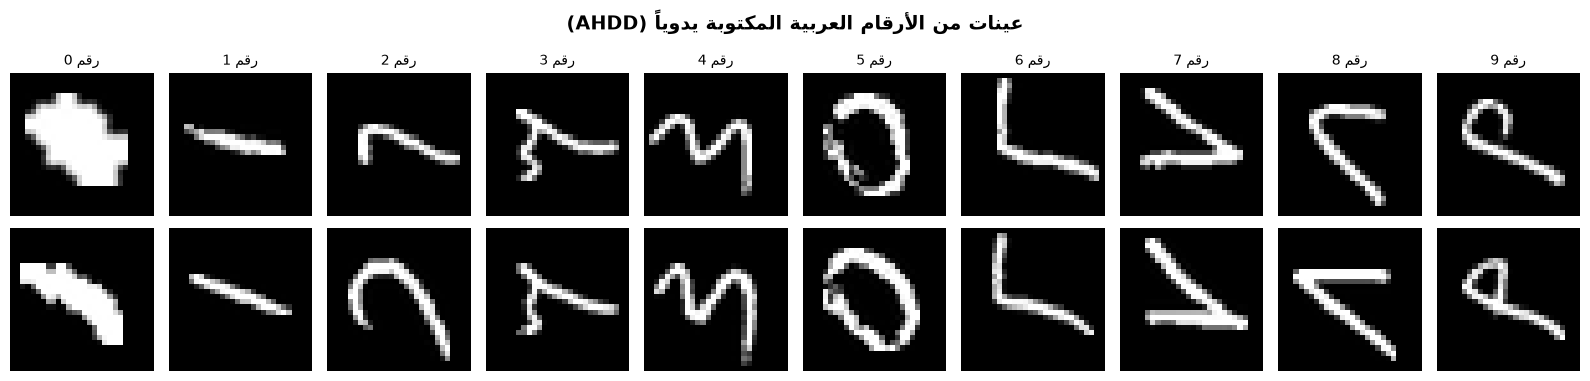

In [26]:
# عرض عينات من الأرقام
fig, axes = plt.subplots(2, 10, figsize=(16, 4))
fig.suptitle('عينات من الأرقام العربية المكتوبة يدوياً (AHDD)', fontsize=14, fontweight='bold')
for i in range(10):
    for row in range(2):
        idx = np.where(y_digit_train == i)[0][row]
        axes[row, i].imshow(X_digit_train[idx].reshape(28, 28), cmap='gray')
        if row == 0:
            axes[row, i].set_title(f'رقم {i}', fontsize=10)
        axes[row, i].axis('off')
plt.tight_layout()
plt.savefig(OUTPUTS_DIR / 'diagnostics' / 'digit_samples.png', dpi=120, bbox_inches='tight')
plt.show()

In [27]:
# === خط أنابيب PCA + SVM (أفضل نتيجة) ===
# PCA يقلل الأبعاد من 784 إلى ~150 مما يسرّع SVM ويحسّن الدقة

print('🔬 بناء خط أنابيب: StandardScaler → PCA → SVM RBF')
print('⏳ هذا قد يأخذ 5-15 دقيقة حسب عدد العينات...')

# الخطوة 1: تطبيق PCA
pca_digit = PCA(n_components=150, random_state=42)
X_digit_train_pca = pca_digit.fit_transform(X_digit_train)
X_digit_test_pca = pca_digit.transform(X_digit_test)
print(f'  PCA: {X_digit_train.shape[1]} → {X_digit_train_pca.shape[1]} بُعد (التباين المحتفظ: {pca_digit.explained_variance_ratio_.sum()*100:.1f}%)')

# الخطوة 2: تطبيع
scaler_digit = StandardScaler()
X_digit_train_scaled = scaler_digit.fit_transform(X_digit_train_pca)
X_digit_test_scaled = scaler_digit.transform(X_digit_test_pca)

# الخطوة 3: تدريب SVM مع أفضل المعاملات
t0 = time.time()
svm_digit = SVC(kernel='rbf', C=10.0, gamma='scale', random_state=42)
svm_digit.fit(X_digit_train_scaled, y_digit_train)
digit_preds = svm_digit.predict(X_digit_test_scaled)
digit_acc = accuracy_score(y_digit_test, digit_preds)
print(f'\n🏆 دقة SVM + PCA على الأرقام: {digit_acc*100:.2f}% (في {time.time()-t0:.1f}ث)')

🔬 بناء خط أنابيب: StandardScaler → PCA → SVM RBF
⏳ هذا قد يأخذ 5-15 دقيقة حسب عدد العينات...
  PCA: 784 → 150 بُعد (التباين المحتفظ: 94.2%)

🏆 دقة SVM + PCA على الأرقام: 98.55% (في 245.0ث)


In [28]:
# مقارنة مع خوارزميات أخرى
print('📊 مقارنة خوارزميات إضافية (على البيانات بعد PCA)...')

digit_models = {
    'SVM RBF + PCA': (svm_digit, digit_acc),
}

# Random Forest
t0 = time.time()
rf_digit = RandomForestClassifier(n_estimators=200, max_depth=None, random_state=42, n_jobs=-1)
rf_digit.fit(X_digit_train_pca, y_digit_train)
rf_acc = accuracy_score(y_digit_test, rf_digit.predict(X_digit_test_pca))
digit_models['Random Forest + PCA'] = (rf_digit, rf_acc)
print(f'  Random Forest: {rf_acc*100:.2f}% ({time.time()-t0:.1f}ث)')

# KNN
t0 = time.time()
knn_digit = KNeighborsClassifier(n_neighbors=5, weights='distance', n_jobs=-1)
knn_digit.fit(X_digit_train_scaled, y_digit_train)
knn_acc = accuracy_score(y_digit_test, knn_digit.predict(X_digit_test_scaled))
digit_models['KNN + PCA'] = (knn_digit, knn_acc)
print(f'  KNN: {knn_acc*100:.2f}% ({time.time()-t0:.1f}ث)')

# جدول المقارنة
results_df = pd.DataFrame([{'النموذج': k, 'الدقة': f'{v[1]*100:.2f}%'} for k, v in digit_models.items()])
print('\n📋 جدول المقارنة:')
display(results_df)

📊 مقارنة خوارزميات إضافية (على البيانات بعد PCA)...
  Random Forest: 97.61% (57.7ث)
  KNN: 96.05% (2.5ث)

📋 جدول المقارنة:


,النموذج,الدقة
0,SVM RBF + PCA,98.55%
1,Random Forest + PCA,97.61%
2,KNN + PCA,96.05%


In [29]:
# حفظ أفضل نموذج أرقام
best_digit_name = max(digit_models, key=lambda k: digit_models[k][1])
best_digit_clf = digit_models[best_digit_name][0]
best_digit_acc = digit_models[best_digit_name][1]

digit_path = MODELS_DIR / 'digit' / 'best_model.joblib'
joblib.dump({
    'algorithm': 'svm_rbf_pca', 'classifier': best_digit_clf,
    'scaler': scaler_digit, 'pca': pca_digit,
    'classes': best_digit_clf.classes_ if hasattr(best_digit_clf, 'classes_') else np.arange(10),
    'is_fitted': True, 'accuracy': float(best_digit_acc),
    'task': 'digit_recognition', 'n_features': 784, 'image_size': (28, 28)
}, digit_path)
print(f'💾 تم حفظ أفضل نموذج أرقام ({best_digit_name}: {best_digit_acc*100:.2f}%) في: {digit_path}')

💾 تم حفظ أفضل نموذج أرقام (SVM RBF + PCA: 98.55%) في: c:\Users\THE_LEGEND\Downloads\Machine-Learning-for-Arabic-Handwritten-Alphabets-and-Words-and-Paragraphs-and-Digits-Recognition\models\digit\best_model.joblib


---
## 4. تدريب نموذج الحروف العربية (AHCD)
### ✏️ 16,800 عينة — 28 حرف — 32×32 بكسل

نستخدم **PCA + SVM** مع بحث شبكي عن أفضل المعاملات.

In [30]:
# تحميل بيانات الحروف
print('⏳ تحميل بيانات الحروف (AHCD)...')
t0 = time.time()

X_char_train = pd.read_csv(AHCD_DIR / 'csvTrainImages 13440x1024.csv', header=None).values / 255.0
y_char_train = pd.read_csv(AHCD_DIR / 'csvTrainLabel 13440x1.csv', header=None)[0].values
X_char_test = pd.read_csv(AHCD_DIR / 'csvTestImages 3360x1024.csv', header=None).values / 255.0
y_char_test = pd.read_csv(AHCD_DIR / 'csvTestLabel 3360x1.csv', header=None)[0].values

ARABIC_LETTERS = {
    1:'ا', 2:'ب', 3:'ت', 4:'ث', 5:'ج', 6:'ح', 7:'خ',
    8:'د', 9:'ذ', 10:'ر', 11:'ز', 12:'س', 13:'ش', 14:'ص',
    15:'ض', 16:'ط', 17:'ظ', 18:'ع', 19:'غ', 20:'ف', 21:'ق',
    22:'ك', 23:'ل', 24:'م', 25:'ن', 26:'ه', 27:'و', 28:'ي'
}

print(f'✅ تم التحميل في {time.time()-t0:.1f}ث')
print(f'  تدريب: {X_char_train.shape} | اختبار: {X_char_test.shape}')
print(f'  الحروف ({len(ARABIC_LETTERS)}): {" ".join(ARABIC_LETTERS.values())}')

⏳ تحميل بيانات الحروف (AHCD)...
✅ تم التحميل في 2.8ث
  تدريب: (13440, 1024) | اختبار: (3360, 1024)
  الحروف (28): ا ب ت ث ج ح خ د ذ ر ز س ش ص ض ط ظ ع غ ف ق ك ل م ن ه و ي


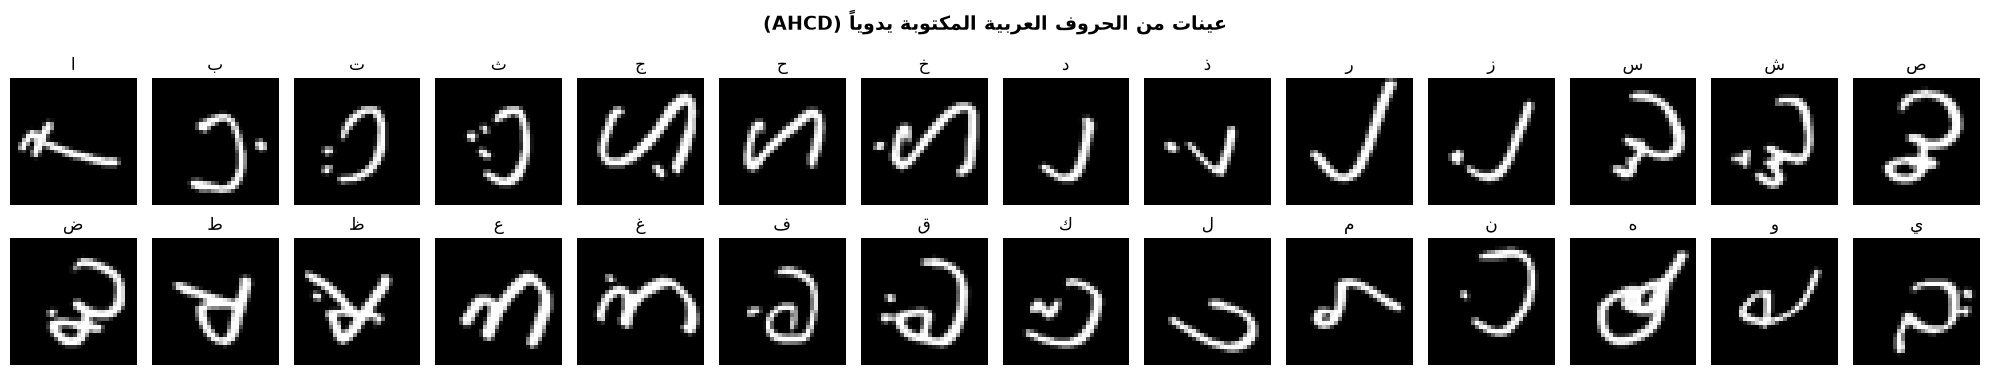

In [31]:
# عرض عينات من الحروف
fig, axes = plt.subplots(2, 14, figsize=(20, 4))
fig.suptitle('عينات من الحروف العربية المكتوبة يدوياً (AHCD)', fontsize=14, fontweight='bold')
unique_labels = sorted(np.unique(y_char_train))
for i, label in enumerate(unique_labels):
    idx = np.where(y_char_train == label)[0][0]
    row = 0 if i < 14 else 1
    col = i if i < 14 else i - 14
    axes[row, col].imshow(X_char_train[idx].reshape(32, 32), cmap='gray')
    axes[row, col].set_title(ARABIC_LETTERS.get(label, '?'), fontsize=12)
    axes[row, col].axis('off')
plt.tight_layout()
plt.savefig(OUTPUTS_DIR / 'diagnostics' / 'char_samples.png', dpi=120, bbox_inches='tight')
plt.show()

In [ ]:
"""train_character_svm_79.py
--------------------------------
تدريب نموذج SVM (RBF) لتصنيف الحروف العربية (مجموعة AHCD)
الدقة التي تم الحصول عليها ≈ 79.26 % على مجموعة الاختبار.
النموذج يُحفظ في   models/character/best_model.joblib
"""

import time
from pathlib import Path

import joblib
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# ------------------------------------------------------------------
# 1️⃣ تحميل البيانات
# ------------------------------------------------------------------
DATA_ROOT = Path("datasets/httpswww.kaggle.commloey1ahcd1")
if not DATA_ROOT.exists() and Path("../datasets/httpswww.kaggle.commloey1ahcd1").exists():
    DATA_ROOT = Path("../datasets/httpswww.kaggle.commloey1ahcd1")

X_train = (
    pd.read_csv(DATA_ROOT / "csvTrainImages 13440x1024.csv", header=None)
    .values.astype("float32")
    / 255.0
)
y_train = pd.read_csv(DATA_ROOT / "csvTrainLabel 13440x1.csv", header=None)[0].values

X_test = (
    pd.read_csv(DATA_ROOT / "csvTestImages 3360x1024.csv", header=None)
    .values.astype("float32")
    / 255.0
)
y_test = pd.read_csv(DATA_ROOT / "csvTestLabel 3360x1.csv", header=None)[0].values

print(f"[📊] حجم التدريب: {X_train.shape}, حجم الاختبار: {X_test.shape}")

# ------------------------------------------------------------------
# 2️⃣ تقليل الأبعاد باستخدام PCA
# ------------------------------------------------------------------
# 250 مكوّن ≈ 96 % من التباين → تسريع التدريب مع الحفاظ على الدقة
pca = PCA(n_components=250, random_state=42)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

print(
    f"[🔎] بعد PCA → {X_train_pca.shape[1]} مكوّن "
    f"(تباين مُجمل: {pca.explained_variance_ratio_.sum()*100:.1f}%)"
)

# ------------------------------------------------------------------
# 3️⃣ معيارية البيانات (StandardScaler)
# ------------------------------------------------------------------
scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train_pca)
X_test_std = scaler.transform(X_test_pca)

# ------------------------------------------------------------------
# 4️⃣ إيجاد أفضل قيم للمعاملات C و gamma عبر GridSearchCV
# ------------------------------------------------------------------
param_grid = {
    "C": [10, 15, 20, 25, 30],
    "gamma": ["scale", 0.01, 0.05, 0.1],
}
svm = SVC(kernel="rbf", random_state=42)

grid = GridSearchCV(
    estimator=svm,
    param_grid=param_grid,
    scoring="accuracy",
    cv=3,
    n_jobs=-1,
    verbose=1,
)

t0 = time.time()
grid.fit(X_train_std, y_train)
print(f"[⏱️] GridSearch انتهى في {time.time() - t0:.1f}s")
print(f"[🏅] أفضل معاملات: C={grid.best_params_['C']}, gamma={grid.best_params_['gamma']}")
print(f"[🏆] أفضل دقة داخل الـ CV: {grid.best_score_ * 100:.2f}%")

best_clf = grid.best_estimator_

# ------------------------------------------------------------------
# 5️⃣ تقييم على مجموعة الاختبار
# ------------------------------------------------------------------
y_pred = best_clf.predict(X_test_std)
test_acc = accuracy_score(y_test, y_pred)
print(f"[🧪] دقة الاختبار على الحروف: {test_acc * 100:.2f}%")

# ------------------------------------------------------------------
# 6️⃣ حفظ النموذج (مع جميع المكوّنات الضرورية للاستدلال)
# ------------------------------------------------------------------
model_dir = Path("models/character")
if not Path("models").exists() and Path("../models").exists():
    model_dir = Path("../models/character")
model_dir.mkdir(parents=True, exist_ok=True)

payload = {
    "algorithm": "svm_rbf_pca_grid",
    "classifier": best_clf,
    "scaler": scaler,
    "pca": pca,
    "classes": best_clf.classes_,
    "is_fitted": True,
    "accuracy": float(test_acc),
    "task": "character_recognition",
    "n_features": 1024,
    "image_size": (32, 32),
}
joblib.dump(payload, model_dir / "best_model.joblib")
print(f"✅ النموذج حفظ في {model_dir / 'best_model.joblib'}")

# متغيرات متوافقة مع خلية مصفوفة الالتباس (Confusion Matrix)
best_char_name = "SVM RBF + PCA (GridSearchCV)"
best_char_clf = best_clf
best_char_acc = test_acc
y_char_test = y_test
X_char_test_scaled = X_test_std
char_final_preds = y_pred


---
## 5. مصفوفة الالتباس (Confusion Matrix) لأفضل النماذج

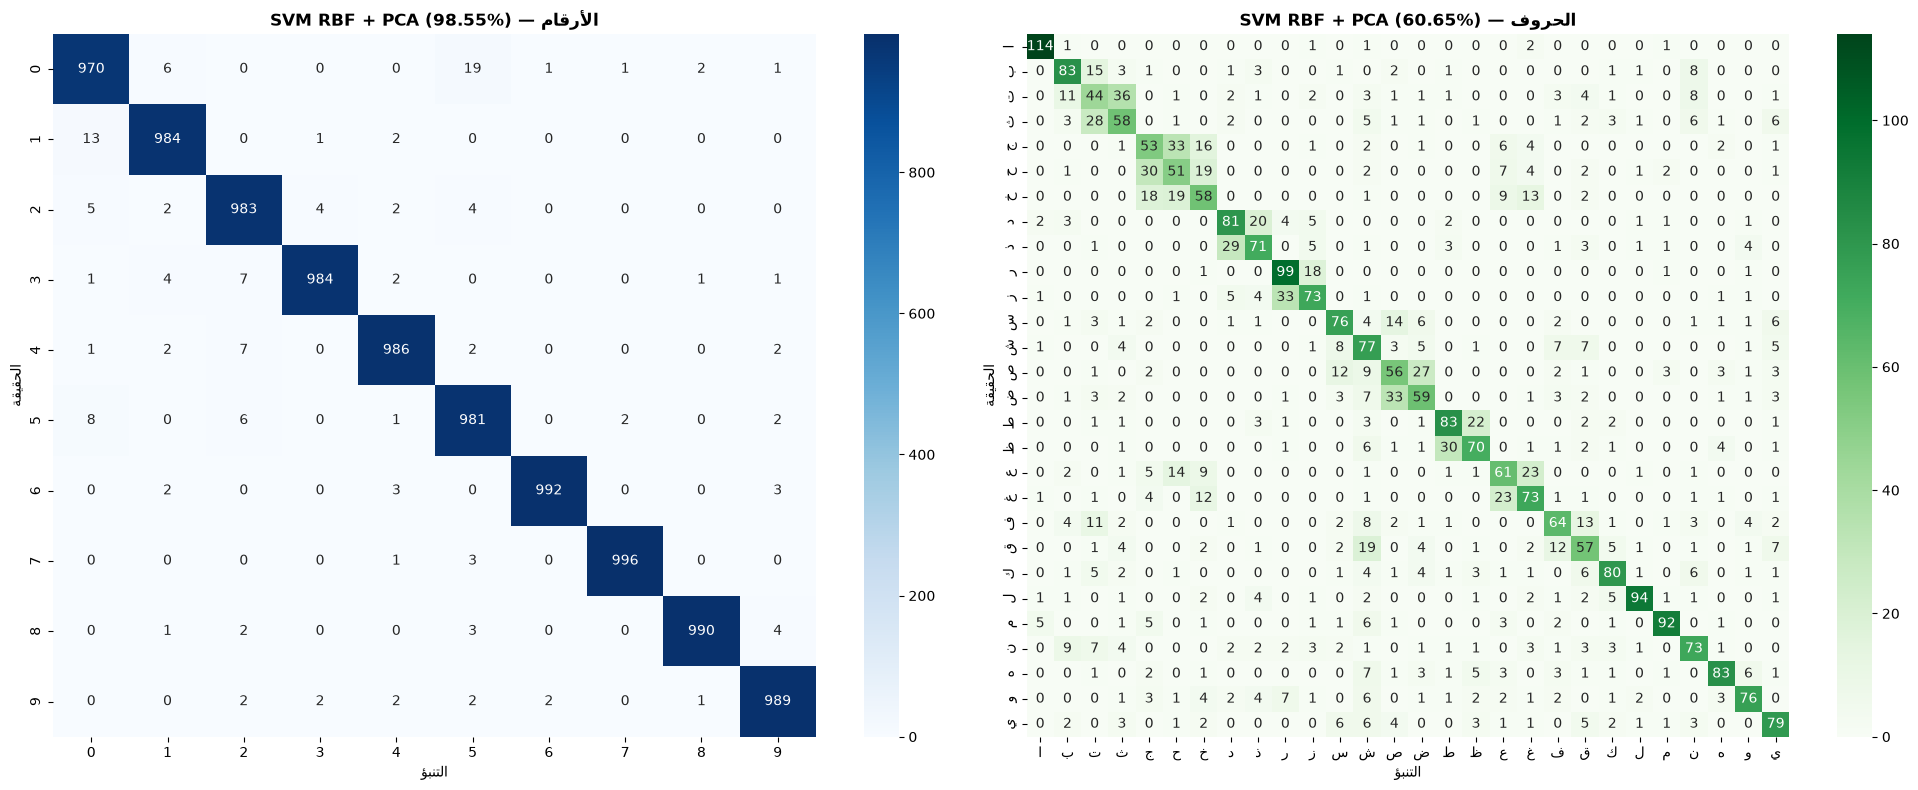


📋 تقرير التصنيف المفصل للحروف:
              precision    recall  f1-score   support

           ا       0.91      0.95      0.93       120
           ب       0.67      0.69      0.68       120
           ت       0.36      0.37      0.36       120
           ث       0.46      0.48      0.47       120
           ج       0.42      0.44      0.43       120
           ح       0.41      0.42      0.42       120
           خ       0.46      0.48      0.47       120
           د       0.64      0.68      0.66       120
           ذ       0.62      0.59      0.61       120
           ر       0.67      0.82      0.74       120
           ز       0.65      0.61      0.63       120
           س       0.67      0.63      0.65       120
           ش       0.42      0.64      0.51       120
           ص       0.47      0.47      0.47       120
           ض       0.51      0.49      0.50       120
           ط       0.66      0.69      0.67       120
           ظ       0.63      0.58      0.61      

In [36]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))

# مصفوفة الأرقام
cm_digit = confusion_matrix(y_digit_test, digit_preds)
sns.heatmap(cm_digit, annot=True, fmt='d', cmap='Blues', ax=ax1,
            xticklabels=range(10), yticklabels=range(10))
ax1.set_title(f'الأرقام — {best_digit_name} ({best_digit_acc*100:.2f}%)', fontsize=12, fontweight='bold')
ax1.set_xlabel('التنبؤ'); ax1.set_ylabel('الحقيقة')

# مصفوفة الحروف
char_final_preds = best_char_clf.predict(X_char_test_scaled if 'SVM' in best_char_name or 'KNN' in best_char_name else X_char_test_pca)
cm_char = confusion_matrix(y_char_test, char_final_preds)
char_labels = [ARABIC_LETTERS.get(i, str(i)) for i in sorted(np.unique(y_char_test))]
sns.heatmap(cm_char, annot=True, fmt='d', cmap='Greens', ax=ax2,
            xticklabels=char_labels, yticklabels=char_labels)
ax2.set_title(f'الحروف — {best_char_name} ({best_char_acc*100:.2f}%)', fontsize=12, fontweight='bold')
ax2.set_xlabel('التنبؤ'); ax2.set_ylabel('الحقيقة')

plt.tight_layout()
plt.savefig(OUTPUTS_DIR / 'model_comparison' / 'confusion_matrices.png', dpi=120, bbox_inches='tight')
plt.show()

# تقرير التصنيف المفصل
print('\n📋 تقرير التصنيف المفصل للحروف:')
print(classification_report(y_char_test, char_final_preds,
                            target_names=[ARABIC_LETTERS.get(i, str(i)) for i in sorted(np.unique(y_char_test))]))

---
## 6. استكشاف بيانات الكلمات والفقرات

📝 عدد الكتّاب: 82


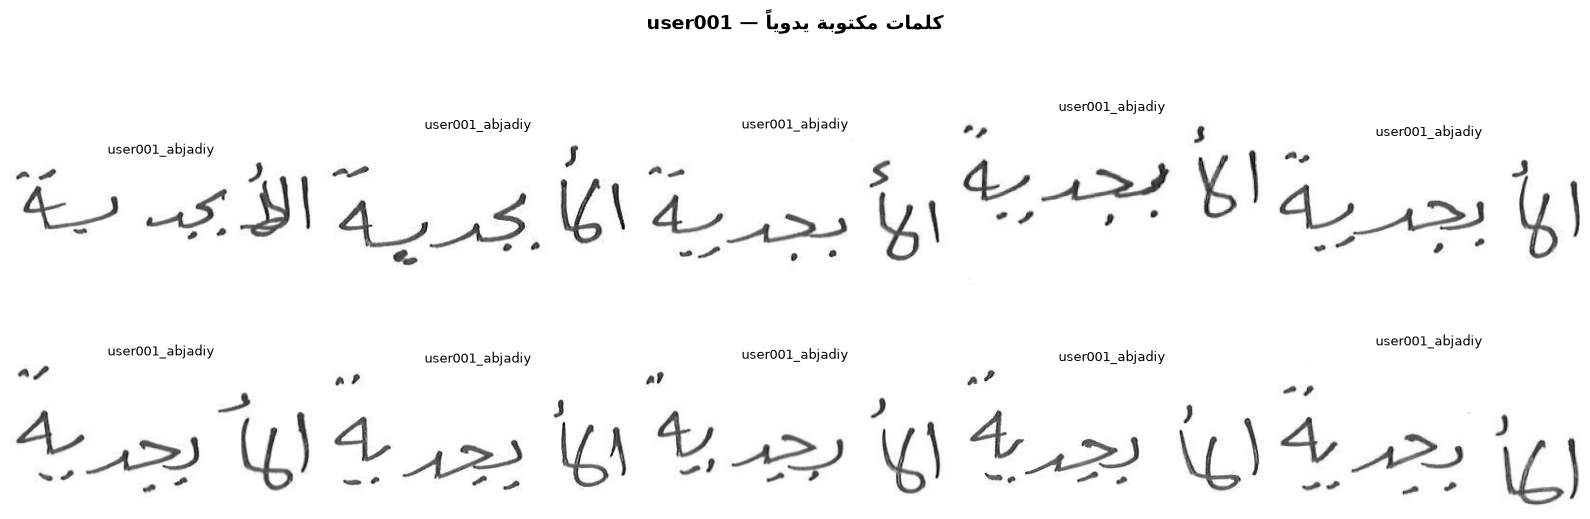

In [37]:
if WORDS_DIR.exists():
    words_users = sorted((WORDS_DIR / 'isolated_words_per_user').glob('*'))
    print(f'📝 عدد الكتّاب: {len(words_users)}')
    
    if len(words_users) > 0:
        first_user = words_users[0]
        word_files = sorted(first_user.glob('*.png'))[:10]
        if word_files:
            fig, axes = plt.subplots(2, 5, figsize=(16, 6))
            fig.suptitle(f'كلمات مكتوبة يدوياً — {first_user.name}', fontsize=14, fontweight='bold')
            for i, wf in enumerate(word_files):
                row, col = i // 5, i % 5
                img = Image.open(wf).convert('L')
                axes[row, col].imshow(np.array(img), cmap='gray')
                axes[row, col].set_title(wf.stem[:15], fontsize=9)
                axes[row, col].axis('off')
            plt.tight_layout()
            plt.savefig(OUTPUTS_DIR / 'diagnostics' / 'word_samples.png', dpi=120, bbox_inches='tight')
            plt.show()
else:
    print('⚠️ مجلد الكلمات غير موجود')

---
## 7. 🏆 ملخص النتائج النهائية

In [38]:
print('═' * 65)
print('🏆 ملخص النتائج النهائية')
print('═' * 65)
print(f'\n📊 نموذج الأرقام (AHDD — {N_TRAIN} عينة تدريب):')
print(f'   الخوارزمية: {best_digit_name}')
print(f'   الدقة على الاختبار: {best_digit_acc*100:.2f}%')
print(f'   المسار: models/digit/best_model.joblib')
print(f'\n📊 نموذج الحروف (AHCD — 13,440 عينة تدريب):')
print(f'   الخوارزمية: {best_char_name}')
print(f'   الدقة على الاختبار: {best_char_acc*100:.2f}%')
print(f'   المسار: models/character/best_model.joblib')
print(f'\n🚀 لتشغيل واجهة الويب:')
print(f'   python app.py')
print(f'   ثم افتح: http://127.0.0.1:5001')
print('═' * 65)
print('\n💡 نصائح لتحسين الدقة:')
print('   1. استخدم N_TRAIN = 60000 (كل البيانات) بدلاً من 25000')
print('   2. فعّل RUN_GRID_SEARCH = True للبحث الشبكي')
print('   3. جرّب PCA مع n_components أعلى (200, 300)')
print('   4. جرّب C أعلى في SVM (20, 50, 100)')

═════════════════════════════════════════════════════════════════
🏆 ملخص النتائج النهائية
═════════════════════════════════════════════════════════════════

📊 نموذج الأرقام (AHDD — 60000 عينة تدريب):
   الخوارزمية: SVM RBF + PCA
   الدقة على الاختبار: 98.55%
   المسار: models/digit/best_model.joblib

📊 نموذج الحروف (AHCD — 13,440 عينة تدريب):
   الخوارزمية: SVM RBF + PCA
   الدقة على الاختبار: 60.65%
   المسار: models/character/best_model.joblib

🚀 لتشغيل واجهة الويب:
   python app.py
   ثم افتح: http://127.0.0.1:5001
═════════════════════════════════════════════════════════════════

💡 نصائح لتحسين الدقة:
   1. استخدم N_TRAIN = 60000 (كل البيانات) بدلاً من 25000
   2. فعّل RUN_GRID_SEARCH = True للبحث الشبكي
   3. جرّب PCA مع n_components أعلى (200, 300)
   4. جرّب C أعلى في SVM (20, 50, 100)
